In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

In [2]:
data = {
    'Hours': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    'Marks': [35, 40, 45, 50, 55, 60, 65, 70, 80, 85]
}

In [3]:
df = pd.DataFrame(data)
df

,Hours,Marks
0,1,35
1,2,40
2,3,45
3,4,50
4,5,55
5,6,60
6,7,65
7,8,70
8,9,80
9,10,85


In [4]:
X = df[['Hours']]
y = df['Marks']

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [6]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [7]:
model = SVR(kernel='linear')

In [8]:
model.fit(X_train_scaled, y_train)

,kernel,'linear'
,degree,3
,gamma,'scale'
,coef0,0.0
,tol,0.001
,C,1.0
,epsilon,0.1
,shrinking,True
,cache_size,200
,verbose,False
,max_iter,-1


In [9]:
y_pred = model.predict(X_test_scaled)

In [12]:
print(y_test.values)

[80 40]


In [13]:
y_pred

array([66.18965517, 48.81034483])

In [14]:
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)


In [15]:
mse

134.17390011890603

In [16]:
r2

0.6645652497027349

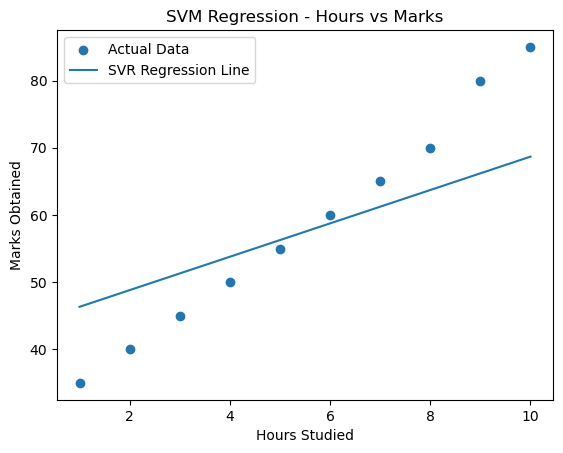

In [17]:
plt.scatter(X, y, label="Actual Data")

X_all_scaled = scaler.transform(X)
y_all_pred = model.predict(X_all_scaled)

plt.plot(X, y_all_pred, label="SVR Regression Line")

plt.xlabel("Hours Studied")
plt.ylabel("Marks Obtained")
plt.title("SVM Regression - Hours vs Marks")
plt.legend()
plt.show()

In [18]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score


In [19]:
data = {
    'Hours': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    'Marks': [35, 40, 45, 50, 55, 60, 65, 70, 80, 85]
}

In [20]:
df = pd.DataFrame(data)

In [21]:
df

,Hours,Marks
0,1,35
1,2,40
2,3,45
3,4,50
4,5,55
5,6,60
6,7,65
7,8,70
8,9,80
9,10,85


In [22]:
X = df[['Hours']]
y = df['Marks']


In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [24]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
linear_pred = linear_model.predict(X_test)


In [25]:
ridge_model = Ridge(alpha=1.0)
ridge_model.fit(X_train, y_train)
ridge_pred = ridge_model.predict(X_test)


In [26]:
lasso_model = Lasso(alpha=1.0)
lasso_model.fit(X_train, y_train)
lasso_pred = lasso_model.predict(X_test)

In [27]:
r2_score(y_test, linear_pred)

0.987949149078478

In [28]:
 r2_score(y_test, ridge_pred)

0.985868318640477

In [29]:
r2_score(y_test, lasso_pred)

0.984609375

In [30]:
 mean_squared_error(y_test, linear_pred)

4.820340368608813

In [31]:
mean_squared_error(y_test, ridge_pred)

5.652672543809226

In [32]:
 mean_squared_error(y_test, lasso_pred)

6.15625

In [33]:
 linear_model.coef_

array([5.38793103])

In [34]:
ridge_model.coef_

array([5.29661017])

In [35]:
lasso_model.coef_

array([5.25])

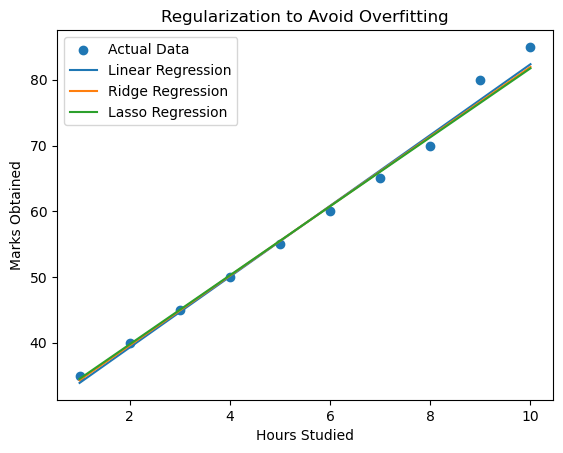

In [36]:
plt.scatter(X, y, label="Actual Data")

plt.plot(X, linear_model.predict(X),
         label="Linear Regression")

plt.plot(X, ridge_model.predict(X),
         label="Ridge Regression")

plt.plot(X, lasso_model.predict(X),
         label="Lasso Regression")

plt.xlabel("Hours Studied")
plt.ylabel("Marks Obtained")
plt.title("Regularization to Avoid Overfitting")
plt.legend()
plt.show()